# DC Generator Electromechanical ModelThis notebook simulates a DC generator with constant field excitation.

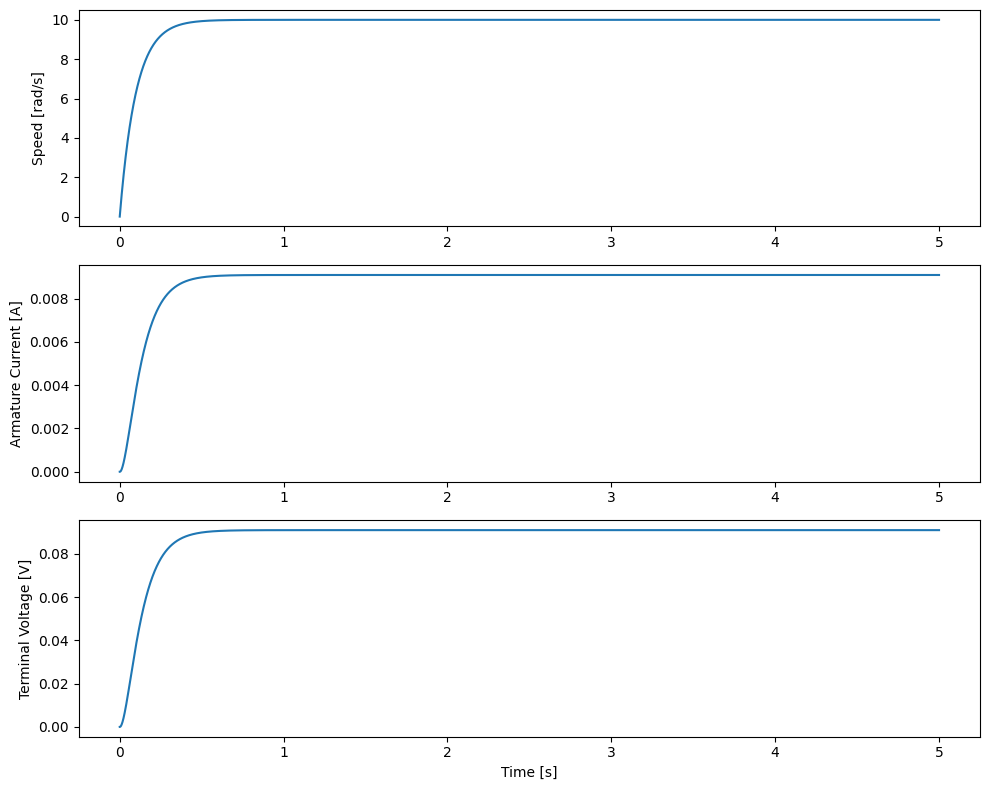

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
J = 0.01    # kg.m^2
B = 0.1     # N.m.s
Ra = 1.0    # Ohm
La = 0.5    # H
Ke = 0.01   # V.s/rad
Kt = 0.01   # N.m/A
RL = 10     # Ohm
Tm = 1.0    # N.m (step torque)

# Simulation settings
t_end = 5
dt = 0.001
n = int(t_end/dt)
t = np.linspace(0, t_end, n)

# State variables
omega = np.zeros(n)
ia = np.zeros(n)

# Simulation loop
for k in range(1, n):
    # Electrical dynamics: La * dia/dt = Ke*omega - (Ra+RL)*ia
    dia = (Ke*omega[k-1] - (Ra+RL)*ia[k-1]) / La
    ia[k] = ia[k-1] + dia*dt

    # Mechanical dynamics: J * domega/dt = Tm - Kt*ia - B*omega
    domega = (Tm - Kt*ia[k-1] - B*omega[k-1]) / J
    omega[k] = omega[k-1] + domega*dt

# Terminal voltage and powers
vt = RL * ia
P_mec = (Kt*ia) * omega
P_el = vt * ia

# Plot
plt.figure(figsize=(10,8))
plt.subplot(3,1,1)
plt.plot(t, omega)
plt.ylabel('Speed [rad/s]')

plt.subplot(3,1,2)
plt.plot(t, ia)
plt.ylabel('Armature Current [A]')

plt.subplot(3,1,3)
plt.plot(t, vt)
plt.ylabel('Terminal Voltage [V]')
plt.xlabel('Time [s]')
plt.tight_layout()
plt.show()